# Тестовое задание — аналитика данных на Python
**Источник:** `Данные для тестового задания (1).xlsx`  
**Вопросы:** `Тестовое задание (1).docx`  

Запускайте ячейки последовательно через **Kernel → Restart & Run All**. Excel-файл должен лежать в одной папке с ноутбуком.

## 0. Импорт библиотек и загрузка данных
При необходимости установите зависимости командой `pip install pandas openpyxl numpy scipy matplotlib`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

path = Path('Данные для тестового задания (1).xlsx')
if not path.exists():
    raise FileNotFoundError(f'Положите Excel-файл рядом с ноутбуком: {path.resolve()}')
aud = pd.read_excel(path, sheet_name='Данные об аудитории')
ab = pd.read_excel(path, sheet_name='Данные АБ тестов')
listers = pd.read_excel(path, sheet_name='Листеры')
aud['date'] = pd.to_datetime(aud['date'])
listers['date'] = pd.to_datetime(listers['date'])
for name, frame in [('Аудитория', aud), ('A/B-тесты', ab), ('Листеры', listers)]:
    print(name, '— строк:', len(frame), '| столбцы:', list(frame.columns))
display(aud.head(), ab.head(), listers.head())

Аудитория — строк: 16814 | столбцы: ['date', 'user_id', 'view_adverts']
A/B-тесты — строк: 2835 | столбцы: ['experiment_num', 'experiment_group', 'user_id', 'revenue']
Листеры — строк: 158 | столбцы: ['user_id', 'date', 'cnt_adverts', 'age', 'cnt_contacts', 'revenue']


,date,user_id,view_adverts
0,2023-11-11,8c020470-8461-11ed-83d0-552e8cc749d6,13
1,2023-11-18,5875f070-7b92-11ee-a6fb-8b298e83f4f7,14
2,2023-11-29,3c2d27c0-4fd6-11eb-b89f-2ffb31b67dd6,21
3,2023-11-29,234a96d0-ad16-11ed-a2e6-793ddfeeba1f,23
4,2023-11-29,4d07c180-644f-11eb-879c-b7c02edf4f37,12


,experiment_num,experiment_group,user_id,revenue
0,1,test,38456,520
1,1,control,13125924,806
2,1,control,9761984,0
3,1,test,11387012,208
4,1,test,18319648,104


,user_id,date,cnt_adverts,age,cnt_contacts,revenue
0,100,2022-01-01,6,21,119,53
1,100,2022-01-02,2,21,200,18
2,100,2022-01-03,6,21,193,42
3,100,2022-01-04,2,21,143,38
4,100,2022-01-05,2,21,190,40


## 1. MAU — уникальные пользователи за ноябрь

In [2]:
mau = aud['user_id'].nunique()
print(f'Ответ №1: MAU = {mau:,} пользователей'.replace(',', ' '))

Ответ №1: MAU = 7 639 пользователей


## 2. DAU — среднее количество уникальных пользователей за день
DAU рассчитывается отдельно для каждой даты. Поскольку варианты ответа содержат одно число, используем **среднее дневное DAU за ноябрь**.

Ответ №2: средний DAU = 560.47 ≈ 560


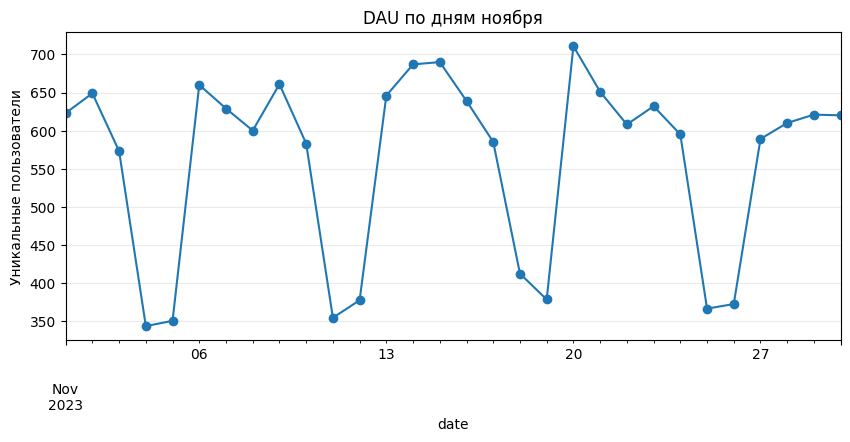

In [3]:
daily = aud.groupby('date')['user_id'].nunique().sort_index()
print(f'Ответ №2: средний DAU = {daily.mean():.2f} ≈ {daily.mean():.0f}')
ax=daily.plot(figsize=(10,4),marker='o',title='DAU по дням ноября'); ax.set_ylabel('Уникальные пользователи');ax.grid(alpha=.25);plt.show()

## 3. Retention первого дня для когорты 1 ноября
Когорта — пользователи, активные 1 ноября; D1 — доля этой когорты, вернувшаяся 2 ноября. В исходных данных нет признака регистрации, поэтому считаем по первому наблюдаемому дню активности.

In [4]:
day0=pd.Timestamp('2023-11-01'); day1=day0+pd.Timedelta(days=1)
u0=set(aud.loc[aud.date.eq(day0),'user_id']);u1=set(aud.loc[aud.date.eq(day1),'user_id'])
retention=len(u0 & u1)/len(u0)*100
print(f'Когорта: {len(u0)}, вернулись D1: {len(u0 & u1)}')
print(f'Ответ №3: D1 Retention = {retention:.2f}%')

Когорта: 623, вернулись D1: 166
Ответ №3: D1 Retention = 26.65%


## 4. Интерпретация retention-кривых
На графике в документе голубая кривая после первоначального снижения стабилизируется около 38% к 7-му дню. Красная кривая падает почти до 0% к 5-му дню. **Вывод:** голубой продукт лучше удерживает пользователей. Для красного продукта стоит изучить ранний отток, улучшить онбординг и повторно проверить удержание после изменений. Числа здесь оценены визуально по графику из DOCX, а не вычислены из Excel.

## 5. Конверсия в просмотр объявления
Числитель — уникальные пользователи с суммарным `view_adverts > 0`, знаменатель — все уникальные пользователи ноября.

In [5]:
views_per_user=aud.groupby('user_id')['view_adverts'].sum()
conversion=(views_per_user>0).mean()*100
print(f'Ответ №5: конверсия = {conversion:.2f}%')

Ответ №5: конверсия = 46.31%


## 6. Среднее число просмотров объявлений на пользователя

In [6]:
avg_views=aud['view_adverts'].sum()/mau
print(f'Ответ №6: {avg_views:.2f} просмотра на уникального пользователя')

Ответ №6: 2.87 просмотра на уникального пользователя


## 7. NPS

In [7]:
nps=(1200/2000-500/2000)*100
print(f'Ответ №7: NPS = {nps:.0f}%')

Ответ №7: NPS = 35%


## 8. Три независимых A/B-теста: ARPU и p-value
ARPU = сумма выручки / число пользователей в группе. Для проверки различий средних используем **двусторонний t-тест Уэлча** (`equal_var=False`), который не требует равенства дисперсий. Выручка может быть асимметричной и содержать много нулей; результаты желательно дополнительно проверять бутстрэпом и анализом выбросов. Уровень значимости α = 0,05.

,Эксперимент,n control,n test,ARPU control,ARPU test,Изменение %,p-value,Значимо (α=0.05)
0,1,465,480,722.46,665.74,-7.85,0.68897,False
1,2,465,480,704.65,332.93,-52.75,0.00113,True
2,3,465,480,663.21,998.67,50.58,0.06032,False


Эксперимент 1: p=0.6890, значимость не достигнута
Эксперимент 2: p=0.0011, значимое различие
Эксперимент 3: p=0.0603, значимость не достигнута


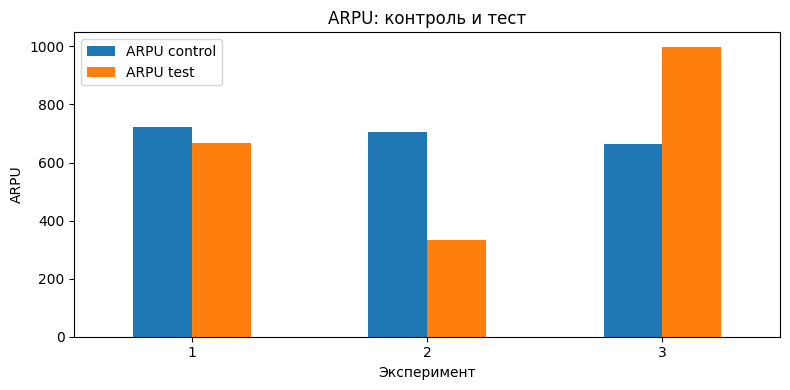

In [8]:
results=[]
for exp, part in ab.groupby('experiment_num'):
    control=part.loc[part.experiment_group.eq('control'),'revenue'].dropna()
    test=part.loc[part.experiment_group.eq('test'),'revenue'].dropna()
    p=stats.ttest_ind(test,control,equal_var=False).pvalue
    results.append({'Эксперимент':exp,'n control':len(control),'n test':len(test),
                    'ARPU control':control.mean(),'ARPU test':test.mean(),
                    'Изменение %':(test.mean()/control.mean()-1)*100,'p-value':p,
                    'Значимо (α=0.05)':p<0.05})
res=pd.DataFrame(results)
display(res.round({'ARPU control':2,'ARPU test':2,'Изменение %':2,'p-value':5}))
for r in res.itertuples(index=False):
    verdict='значимое различие' if r[-1] else 'значимость не достигнута'
    print(f'Эксперимент {r[0]}: p={r[6]:.4f}, {verdict}')
ax=res.set_index('Эксперимент')[['ARPU control','ARPU test']].plot(kind='bar',figsize=(8,4),rot=0)
ax.set_title('ARPU: контроль и тест');ax.set_ylabel('ARPU');plt.tight_layout();plt.show()

**Рекомендации:**
- **Эксперимент 1:** статистически значимого эффекта нет; не внедрять изменение только на основании этого теста.
- **Эксперимент 2:** статистически значимое снижение ARPU; тестовый вариант не внедрять.
- **Эксперимент 3:** наблюдается большой положительный эффект, но p-value немного выше 0,05; победу не объявлять, проверить выбросы и мощность, затем запланировать новый тест.

При одновременной оценке нескольких гипотез стоит учесть множественное тестирование (например, поправку Бонферрони: 0,05/3).

## 9. Средний доход на пользователя по листерам
Суммируем доход по всем строкам и делим на число уникальных пользователей, а не на число записей.

In [9]:
mean_rev=listers.revenue.sum()/listers.user_id.nunique()
print(f'Ответ №9: средний доход на пользователя = {mean_rev:.2f}')

Ответ №9: средний доход на пользователя = 156.48


## 10. Медианный возраст пользователя
Сначала оставляем одну запись на пользователя, чтобы пользователи с несколькими датами не получали лишний вес.

In [10]:
age_by_user=listers.groupby('user_id')['age'].first()
print(f'Ответ №10: медианный возраст = {age_by_user.median():.0f} лет')

Ответ №10: медианный возраст = 28 лет


## 11. График разброса цен
**Ответ: box plot и гистограмма.** Box plot удобен для сравнения распределений между магазинами, гистограмма — для изучения частот и формы распределения.

## 12. Бимодальное распределение
**Ответ: № 3.** На гистограмме видны два пика.

## 13. Наибольшая дисперсия
**Ответ: № 3.** Распределение имеет наибольший разброс по оси X (сравниваем шкалы, а не высоту столбцов).

## 14. Корреляция
**Ответ: Scatter Plot и Correlation Heatmap (1 и 3).** Первый позволяет увидеть связь между парными наблюдениями, второй непосредственно показывает рассчитанные коэффициенты.

## 15. p-value = 0,05
**Ответ: вариант 2.** При верной нулевой гипотезе вероятность получить наблюдаемую статистику или еще более экстремальную равна 5%. Это не вероятность истинности гипотезы.

## 16. Равенство средних двух нормальных выборок
**Ответ: t-тест (вариант 1).**

## 17. Квартили
**Ответ: вариант 2.** Квартили разделяют упорядоченные наблюдения на четыре части по 25%.

## 18. Проверка разницы конверсий для A и B
**Важное ограничение:** в условии указано число *платежей*, а не число *уникальных плательщиков*. Двухпропорциональный z-тест допустим только если каждый посетитель мог дать не более одного учитываемого платежа (либо платежи — это действительно число уникальных плательщиков). Иначе нужен пользовательский датасет и другой подход к тестированию.

In [11]:
visitors_a, payments_a=100_047_501,1003
visitors_b, payments_b=100_001_055,1099
rate_a=payments_a/visitors_a
rate_b=payments_b/visitors_b
uplift=(rate_b/rate_a-1)*100
pooled=(payments_a+payments_b)/(visitors_a+visitors_b)
se=np.sqrt(pooled*(1-pooled)*(1/visitors_a+1/visitors_b))
z=(rate_b-rate_a)/se
p18=2*stats.norm.sf(abs(z))
print(f'A: {rate_a*100:.6f}%, B: {rate_b*100:.6f}%')
print(f'Относительное изменение: {uplift:+.2f}%')
print(f'z={z:.4f}; p-value={p18:.5f}')
print('Значимо на 5% уровне' if p18<.05 else 'Нет значимости на 5% уровне')

A: 0.001003%, B: 0.001099%
Относительное изменение: +9.62%
z=2.1046; p-value=0.03533
Значимо на 5% уровне


**Рекомендация:** при допущении о независимых бинарных конверсиях B статистически лучше A на уровне 5%. Перед внедрением проверить уникальность плательщиков, качество рандомизации, SRM, отсутствие досрочного подглядывания в тест и экономический эффект (выручка, а не только число платежей). Без этих проверок окончательный вывод делать рано.

---
### Итог
Все 18 вопросов разобраны. Ответы № 1–3, 5–10 и 18 воспроизводятся кодом на исходном Excel. Вопросы № 4 и 11–17 интерпретированы по графикам и формулировкам из документа.